# Treinar e comparar modelos

Este notebook ajusta modelos sem rótulos usando apenas o treino e compara seus scores na validação. O teste não participa da escolha. A execução grava modelos em `ml/artifacts/` e congela a seleção em `ml/reports/selecao_validacao.json`.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)


## Três abordagens

1. **Desvio histórico:** score = desvio padronizado absoluto no log do valor; exige cinco transações anteriores.
2. **Isolation Forest:** 250 árvores, amostras de até 512 registros, seed 42. Scores invertidos para que valores maiores indiquem maior anomalia.
3. **Autoencoder:** rede MLP com camadas 32 → 8 → 32, ReLU e saída linear, treinada para reconstruir a matriz; score = erro quadrático médio de reconstrução. Até 150 épocas, sem validação aleatória para early stopping.

O autoencoder usa `MLPRegressor(X, X)` do scikit-learn e não exige GPU ou TensorFlow. Todos os modelos aprendidos recebem a mesma matriz (padronização numérica e one-hot ajustados só em 2024). O baseline usa apenas a referência histórica. A base de treino inclui anomalias desconhecidas; não há filtragem pelo gabarito.

In [2]:
from ml.experiment import train
validation_metrics = train()
columns = ["modelo", "average_precision", "roc_auc", "precision", "recall", "f1", "taxa_alerta", "limiar"]
display(style_table(validation_metrics[columns].round(4)))


Treinando Desvio historico...


Treinando Isolation Forest...


Treinando Autoencoder...


modelo,average_precision,roc_auc,precision,recall,f1,taxa_alerta,limiar
Desvio historico,0.981200,0.985900,0.986000,0.950700,0.968000,0.058200,1.681200
Isolation Forest,0.795600,0.980100,0.864800,0.793700,0.827700,0.055400,0.392900
Autoencoder,0.294400,0.837000,0.291700,0.533600,0.377200,0.110500,0.060600


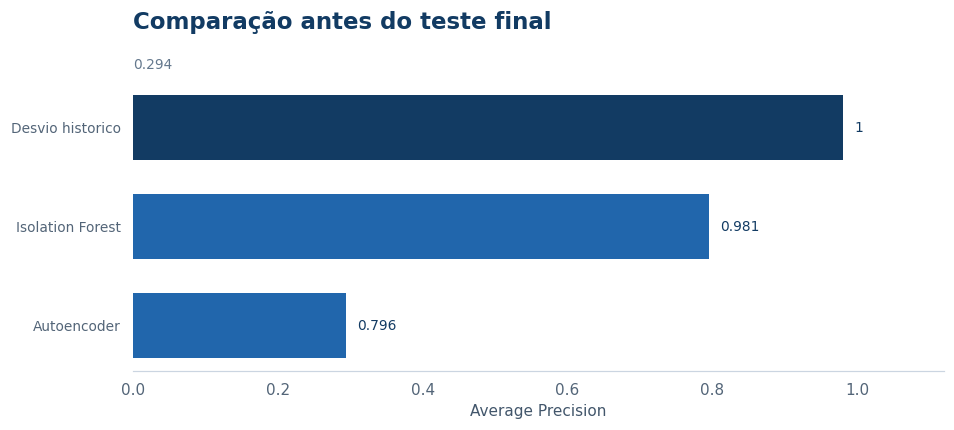

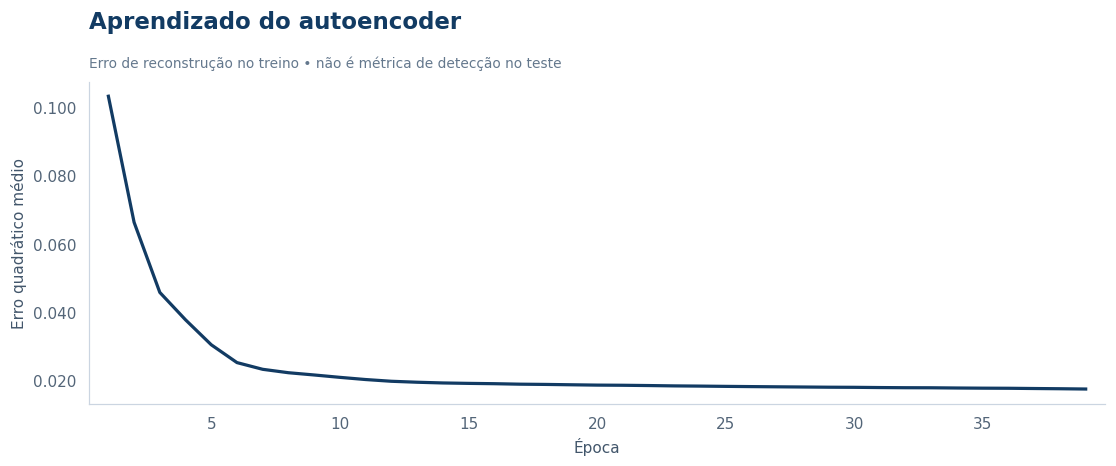

In [3]:
from ml.diagnostics import validation_figures
figures = validation_figures()
for i, figure in enumerate(figures, 1):
    save_figure(figure, f"validacao_{i:02d}", "experimento")
    display(figure)
    plt.close(figure)


## Escolha congelada

A maior Average Precision escolhe o modelo; empates usam F1 e nome. Cada limiar maximiza F1 na validação (empate: maior limiar). Isso é **calibração com rótulos de validação**, embora o ajuste dos pesos seja não supervisionado. AP é a média ponderada das precisões ao longo do recall, não a integral trapezoidal da curva. Não há obrigação de uma rede neural superar uma regra contextual.

In [4]:
import json
selection = json.loads((REPORTS / "selecao_validacao.json").read_text(encoding="utf-8"))
display(Markdown(f"**Modelo selecionado antes do teste: {selection['selecionado']}.**"))
for name, info in selection["modelos"].items():
    if info["avisos"]:
        print(name, info["avisos"])


**Modelo selecionado antes do teste: Desvio historico.**